# 低温ガスの H₂ と熱収支

現行 EQCLib と CHIMES matched を、水素核密度 $n_{\rm H}=3,10,30,100\,\mathrm{cm^{-3}}$ で比較します。気相の H・He・C・O・Si の数比、$G_0=1.7$ Habing、一次宇宙線電離率 $1.8\times10^{-17}\,\mathrm{s^{-1}}$、柱密度 $N_{\rm H}=10^{20}\sqrt{n_{\rm H}/\mathrm{cm^{-3}}}\,\mathrm{cm^{-2}}$、ダスト温度 10 K、乱流ドップラー幅 $3\,\mathrm{km\,s^{-1}}$ をそろえます。軟 X 線と電離光は無効です。CHIMES は EUV を削除した B87 スペクトルを使い、EQCLib はスカラーの $G_0$ を使います。

リポジトリのルートから計算し、ノートブックの全セルを実行します。 [設定と再実行手順](../test/chimes/shielded/README.md#低温ガスの現行モデル比較)

```sh
bash test/chimes/shielded/run_h2_prescription_comparison.sh --current-only
bash test/chimes/shielded/run_thermal_balance_comparison.sh --current-only
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

cwd = Path.cwd().resolve()
repo = next(
    (path for path in (cwd, *cwd.parents, cwd / "EQCLib")
     if (path / "src/ChemicalEquilibriumCooling.h").is_file()),
    None,
)
if repo is None:
    raise FileNotFoundError("EQCLib のリポジトリ内で実行してください。")
output = repo / "test/out/chimes/shielded"
models = {
    "eqclib": ("EQCLib", "#226c97", "-"),
    "chimes": ("CHIMES matched", "#a04b26", "--"),
}


def read_csv(directory, filename):
    path = output / directory / filename
    if not path.is_file():
        raise FileNotFoundError(f"{path} がありません。上のコマンドで計算してください。")
    return np.atleast_1d(np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8"))


def show_table(columns, rows):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


def plot_positive(axis, x, y, status, model):
    label, color, linestyle = models[model]
    axis.plot(x, np.where((status == 0) & (y > 0), y, np.nan),
              label=label, color=color, linestyle=linestyle)


thermal = {model: read_csv("thermal_balance_current", f"native_{model}.csv") for model in models}
densities = sorted(np.unique(thermal["eqclib"]["nH"]))

## 固定温度での H₂ 分率と冷却率

各コードが求めた化学平衡組成を使います。$f_{\rm H_2}=2n(\mathrm{H}_2)/n_{\rm H}$ です。計算が収束しなかった点では線を途切れさせます。熱平衡温度は、正味加熱が正から負に変わる連続した成功点を対数温度で補間して求めます。

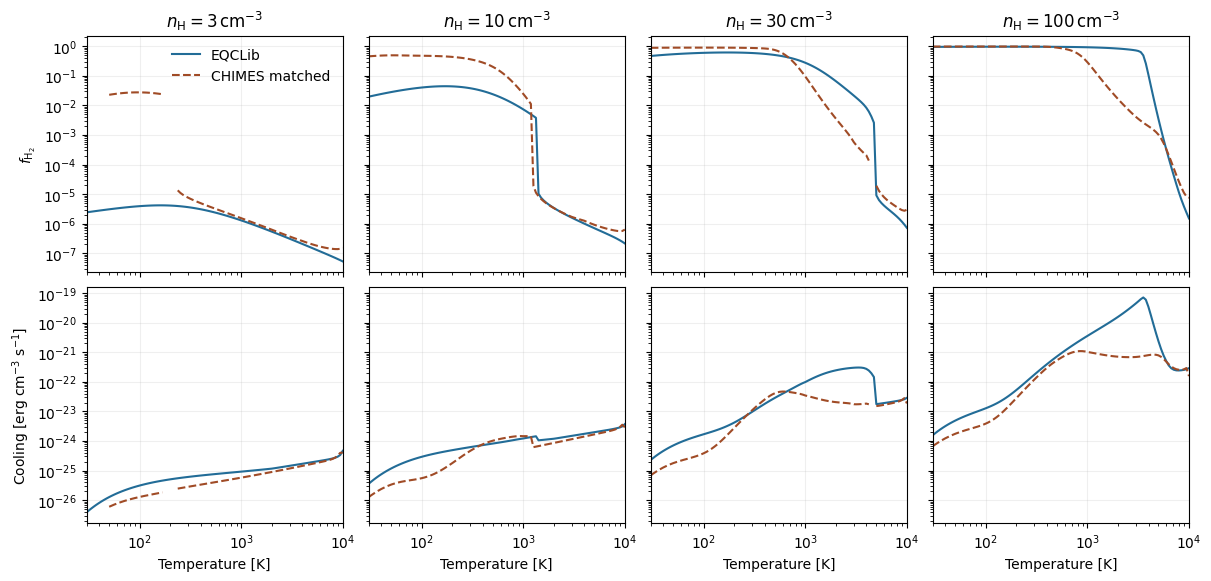

| nH [cm⁻³] | EQCLib [K] | CHIMES matched [K] |
| --- | --- | --- |
| 3 | 286.2 | 1491.0 |
| 10 | 88.9 | 210.9 |
| 30 | 56.3 | 142.6 |
| 100 | 32.9 | 82.1 |

In [2]:
def stable_roots(rows):
    net = (rows["heat"] - rows["cool"]) / np.maximum(rows["heat"] + rows["cool"], 1e-300)
    roots = []
    for i in range(len(rows) - 1):
        if rows["status"][i] == rows["status"][i + 1] == 0 and net[i] >= 0 > net[i + 1]:
            fraction = net[i] / (net[i] - net[i + 1])
            roots.append(rows["T"][i] * (rows["T"][i + 1] / rows["T"][i]) ** fraction)
    return ", ".join(f"{root:.1f}" for root in roots) or "—"


fig, axes = plt.subplots(2, len(densities), figsize=(12, 5.7), sharex=True, sharey="row",
                         layout="constrained")
root_rows = []
for col, density in enumerate(densities):
    roots = []
    for model in models:
        source = thermal[model]
        rows = np.sort(source[source["nH"] == density], order="T")
        roots.append(stable_roots(rows))
        for row, field in enumerate(("fH2", "cool")):
            plot_positive(axes[row, col], rows["T"], rows[field], rows["status"], model)
    root_rows.append([f"{density:g}", *roots])
    axes[0, col].set_title(rf"$n_{{\rm H}}={density:g}\,\mathrm{{cm^{{-3}}}}$")
    axes[1, col].set_xlabel("Temperature [K]")
for axis in axes.flat:
    axis.set(xscale="log", yscale="log", xlim=(30, 1e4))
    axis.grid(alpha=0.2)
axes[0, 0].set_ylabel(r"$f_{\rm H_2}$")
axes[1, 0].set_ylabel(r"Cooling [erg cm$^{-3}$ s$^{-1}$]")
axes[0, 0].legend(frameon=False)
plt.show()

show_table(["nH [cm⁻³]", "EQCLib [K]", "CHIMES matched [K]"], root_rows)

## 同じ温度・組成での加熱と冷却

水素核密度 $10\,\mathrm{cm^{-3}}$ の89 Kと211 Kで、各コードの平衡組成での熱収支を比べます。さらに CHIMES の化学平衡組成の主要成分を両コードに指定し、[C II] の冷却率と電子衝突分を照合します。使った CHIMES の [C II] 表は電子衝突を扱い、EQCLib は H I と H₂ による衝突も含みます。

In [3]:
def rate_at(rows, temperature, sample):
    selected = rows[(rows["nH"] == 10) & (rows["T"] == temperature) &
                    (rows["sample"] == sample) & (rows["status"] == 0)]
    if len(selected) != 1:
        raise ValueError(f"nH=10、{temperature} K の {sample} に成功点が1つ必要です。")
    return selected[0]


columns = ["全加熱", "光電加熱", "全冷却", "[C II]", "[O I]", "H₂"]
fields = ["heat", "heat_pe", "cool", "cool_cii", "cool_oi", "cool_h2"]
rows = []
for temperature in (89, 211):
    for model, (name, _, _) in models.items():
        row = rate_at(thermal[model], temperature, "native")
        rows.append([temperature, name, *[f"{row[field]:.3g}" for field in fields]])
display(Markdown("冷却・加熱率の単位は erg cm⁻³ s⁻¹ です。"))
show_table(["温度 [K]", "モデル", *columns], rows)

rows = []
for model, (name, _, _) in models.items():
    row = rate_at(read_csv("thermal_balance_current", f"shared_{model}.csv"), 89, "chimes_state")
    rows.append([name, f"{row['cool_cii']:.3g}", f"{row['cool_cii_e_only']:.3g}"])
show_table(["同じ指定組成、89 K", "[C II] 全衝突", "[C II] 電子衝突"], rows)

冷却・加熱率の単位は erg cm⁻³ s⁻¹ です。

| 温度 [K] | モデル | 全加熱 | 光電加熱 | 全冷却 | [C II] | [O I] | H₂ |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 89 | EQCLib | 2.6e-25 | 2.57e-25 | 2.61e-25 | 2.56e-25 | 3.49e-27 | 2.62e-28 |
| 89 | CHIMES matched | 2.73e-25 | 2.63e-25 | 5.11e-26 | 4.26e-26 | 3.12e-27 | 4.22e-27 |
| 211 | EQCLib | 2.35e-25 | 2.32e-25 | 5.07e-25 | 4.64e-25 | 3e-26 | 1.18e-26 |
| 211 | CHIMES matched | 2.03e-25 | 1.94e-25 | 2.04e-25 | 4.07e-26 | 2.92e-26 | 1.3e-25 |

| 同じ指定組成、89 K | [C II] 全衝突 | [C II] 電子衝突 |
| --- | --- | --- |
| EQCLib | 1.93e-25 | 5e-26 |
| CHIMES matched | 4.26e-26 | 4.26e-26 |

## 等積冷却履歴と更新時間

各コードの $5{,}000$ K における化学平衡から出発します。EQCLib は平衡モード、CHIMES は非平衡で更新します。速度表は粒子質量 $10^2$ と $10^4 M_\odot$ のクーラン刻みで、両方が成功した同じ条件の CPU 時間を比較します。各条件の時間は1コアで測った反復の中央値です。

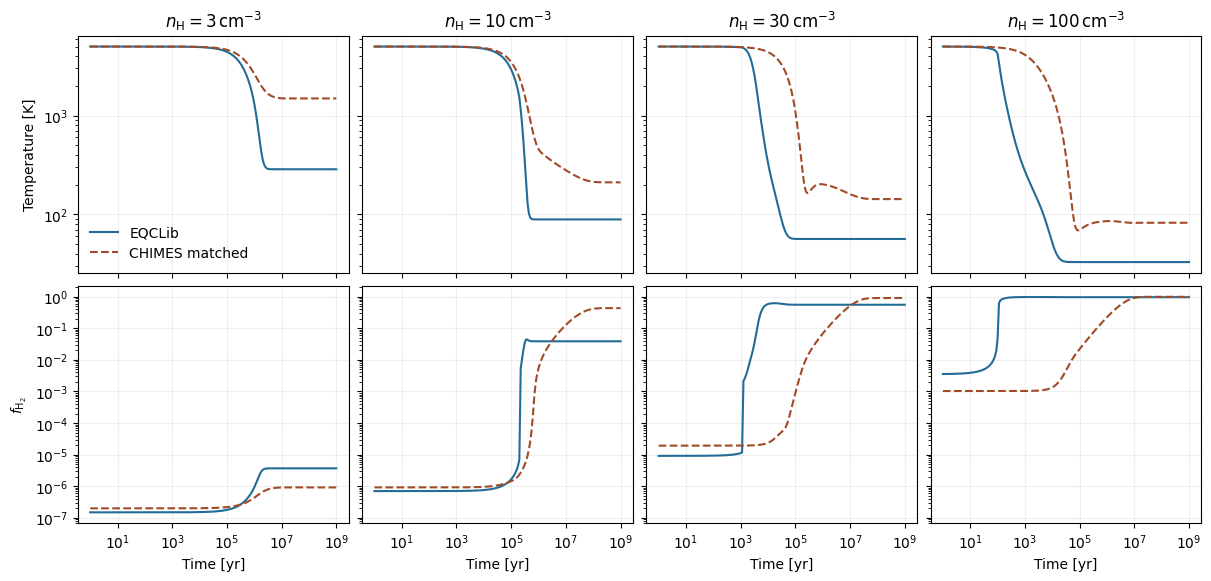

| 粒子質量 [M☉] | 共通セル数 | EQCLib 平均 [µs] | CHIMES 平均 [µs] | 時間の総和の比 CHIMES / EQCLib | 条件別の比の中央値 |
| --- | --- | --- | --- | --- | --- |
| 100 | 27 | 79.8 | 2680.9 | 33.61 | 38.68 |
| 10000 | 27 | 95.3 | 3118.4 | 32.74 | 36.12 |

In [4]:
history_files = {"eqclib": "cooling_eqclib.csv", "chimes": "cooling_chimes_matched.csv"}
fig, axes = plt.subplots(2, len(densities), figsize=(12, 5.7), sharex=True, sharey="row",
                         layout="constrained")
for model, filename in history_files.items():
    source = read_csv("h2_current", filename)
    if model == "eqclib":
        source = source[source["method"] == "eqclib_eq"]
    for col, density in enumerate(densities):
        rows = source[(source["nH"] == density) & (source["t_yr"] > 0)]
        for row, field in enumerate(("T", "fH2")):
            plot_positive(axes[row, col], rows["t_yr"], rows[field], rows["status"], model)
        axes[0, col].set_title(rf"$n_{{\rm H}}={density:g}\,\mathrm{{cm^{{-3}}}}$")
        axes[1, col].set_xlabel("Time [yr]")
for axis in axes.flat:
    axis.set(xscale="log", yscale="log")
    axis.grid(alpha=0.2)
axes[0, 0].set_ylabel("Temperature [K]")
axes[1, 0].set_ylabel(r"$f_{\rm H_2}$")
axes[0, 0].legend(frameon=False)
plt.show()

timing = read_csv("h2_current", "timing.csv")
rows = []
for mass in np.unique(timing["mass_msun"]):
    group = timing[(timing["mass_msun"] == mass) & (timing["status"] == 0)]
    by_model = {
        model: {(row["nH"], row["T0"], row["dt_yr"]): row["cpu_us_median"]
                for row in group if row["variant"] == model}
        for model in ("eqclib", "chimes_matched")
    }
    common = sorted(by_model["eqclib"].keys() & by_model["chimes_matched"].keys())
    if not common:
        raise ValueError(f"粒子質量 {mass:g} の共通成功条件がありません。")
    eq, ch = (np.array([times[key] for key in common]) for times in by_model.values())
    rows.append([f"{mass:g}", len(common), f"{eq.mean():.1f}", f"{ch.mean():.1f}",
                 f"{ch.sum()/eq.sum():.2f}", f"{np.median(ch/eq):.2f}"])
show_table(["粒子質量 [M☉]", "共通セル数", "EQCLib 平均 [µs]", "CHIMES 平均 [µs]",
            "時間の総和の比 CHIMES / EQCLib", "条件別の比の中央値"], rows)